In [1]:
import os
# 规避flashinfer采样防止vllm报错
os.environ["VLLM_USE_FLASHINFER_SAMPLER"] = "0"


In [2]:
import time, torch, gc
from vllm import LLM, SamplingParams
from datasets import load_dataset


W1031 13:26:58.241000 635 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1031 13:26:58.243000 635 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1031 13:26:58.245000 635 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


In [3]:
print(torch.cuda.is_available())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA version:", torch.version.cuda)


True
PyTorch version: 2.14.1+cu132
CUDA available: True
PyTorch CUDA version: 13.2


In [4]:
ds_path = 'synthesis_math_dataset.jsonl'
synthesis_ds = load_dataset('json', data_files=ds_path, split="train")
print(synthesis_ds)


Dataset({
    features: ['d', 'k', 'i', 'q', 'ans', 'W', 'cons'],
    num_rows: 4000
})


## 小实验：Arithmetic Chain（Qwen3-1.7B 思考 vs 不思考）

主实验前的小实验。任务是带小数的加减链：从 `x` 出发按顺序执行 `d` 步 `+ / -`，回答**整条序列（含起点）的最小值**。

**数据**：[synthesis_math_dataset.jsonl](synthesis_math_dataset.jsonl)（串行 `d × k`）。跑满整个 `d × k` 表：`d = 1..20`、`k = 1..10`，每个格子取 `i = 1..5`，共 **1000 题**；两种模式共 **2000 次生成**。

**v2 变更**：C3 增加逐位英文示例，C5 删除 `123 -> 321` 的示例，C6 明确写成 `####ANSWER=RESULT:<answer>`；`max_tokens` 从 2048 提高到 **6144**。旧 2048 结果保留在 `pilot_math_results.jsonl`，新结果写到 `pilot_math_results_v2.jsonl`；旧跑结论见 [record.md](record.md)。

**提示词**：`cons` 放 system message，`q` 放 user message；两种模式共用同一组 messages，只切换 `enable_thinking`。

**采样**：`temperature=0.6`、`top_p=0.95`、`max_tokens=6144`、batch=8；vLLM 加载参数严格按 [AGENTS.md](AGENTS.md) 第 3 节（`gpu_memory_utilization=0.80`、`max_model_len=8192`，未传 `top_k`）。

> 运行环境：vLLM 必须在 WSL (Ubuntu) 中运行；Jupyter 工作目录必须是仓库根目录。运行前建议重启 Kernel；如果已有模型占着显存，先释放，否则 8GB 卡容易 OOM。


In [5]:
from collections import Counter

# ---- 小实验配置 ----
PILOT_PER_CELL = 5  # 每个 (d, k) 格子取 i = 1..5
PILOT_MODEL_PATH = "models/Qwen3-1.7B"
PILOT_MAX_TOKENS = 6144
PILOT_TEMPERATURE = 0.6
PILOT_TOP_P = 0.95
PILOT_BATCH_SIZE = 8
PILOT_RESULTS_PATH = "pilot_math_results_v2.jsonl"

# 总是从磁盘重新加载，避免 Kernel 里残留其他数据集的 synthesis_ds
from datasets import load_dataset
synthesis_ds = load_dataset("json", data_files="synthesis_math_dataset.jsonl", split="train")

pilot_rows = [row for row in synthesis_ds if 1 <= int(row["i"]) <= PILOT_PER_CELL]
cell_counts = Counter((int(row["d"]), int(row["k"])) for row in pilot_rows)
assert len(pilot_rows) == 1000, f"expected 1000 rows, got {len(pilot_rows)}"
assert len(cell_counts) == 200, f"expected 200 (d, k) cells, got {len(cell_counts)}"
assert all(count == PILOT_PER_CELL for count in cell_counts.values()), "each (d, k) cell must have 5 rows"

print(f"pilot rows: {len(pilot_rows)} / {len(synthesis_ds)}")
print("d range:", min(int(r["d"]) for r in pilot_rows), "-", max(int(r["d"]) for r in pilot_rows))
print("k range:", min(int(r["k"]) for r in pilot_rows), "-", max(int(r["k"]) for r in pilot_rows))
print("ans range:", min(float(r["ans"]) for r in pilot_rows), "-", max(float(r["ans"]) for r in pilot_rows))
print("\nfirst question:\n", pilot_rows[0]["q"])
print("\nfirst constraints (truncated):\n", pilot_rows[0]["cons"][:800])


pilot rows: 1000 / 4000
d range: 1 - 20
k range: 1 - 10
ans range: -316.9 - 9.9

first question:
 Start with x = 2.7. Apply the following operations IN ORDER.
1. ( - 16.1 )
What is the minimum value of x, including the starting value?

first constraints (truncated):
 
The final line of your response MUST be exactly in this format:
####ANSWER=<answer>
Where <answer> is your answer
Do not write anything after the #### line.



### 三种准确率与逐条约束判定

- **answer_correct**：从最后一个 `####ANSWER=` 标记提取答案（没有 marker 就算错），数值与参考答案比较；`k=1` 直接比 `ans`，`k>=2` 比 `round_half_up_2(ans)`。
- **constraint_all**：该题适用的前 k 条约束**全部**通过。
- **joint**：`answer_correct and constraint_all`。

| # | 数据集约束 | 判定口径 |
|---|---|---|
| C1 | 最后一行 `####ANSWER=<answer>` | 取最终答案部分最后一行并 strip；`fullmatch` 匹配 `####ANSWER=(.+)`；行尾不能有额外行 |
| C2 | 四舍五入到两位小数 | 小数部分恰好 **2 位**：两位数字，或两个英文数字词；只查格式，不查数值舍入是否正确 |
| C3 | 小数部分用英文单词 | 小数部分必须恰好是 **两个** `ZERO..NINE` 单词，逐位写；`.40` -> `FOUR ZERO`，`.05` -> `ZERO FIVE`，`.00` -> `ZERO ZERO` |
| C4 | 英文单词大写 | 最终答案部分没有小写字母（`text == text.upper()`） |
| C5 | 整数部分倒序 | 整数部分（Z/O/T 解码后）与参考答案两位小数舍入后的整数倒序一致；忽略前导 0，负号一致 |
| C6 | 最终答案以 `RESULT:` 开头 | `####ANSWER=` 后面的 body 以精确的 `RESULT:` 开头，例如 `####ANSWER=RESULT:...`；**不允许**把 `RESULT:` 单独放在 `####ANSWER` 前一行 |
| C7 | 最终答案不超过 12 个空白分隔 token | 含 `####ANSWER=` 的那一行 `split()` 后长度 ≤ 12 |
| C8 | 数字 0/1/2 替换为 Z/O/T | 只检查主数字：整数部分只能匹配 `[3-9ZOT]`；若小数用数字，也检查。`[n]` 后缀不参与 C8 |
| C9 | 追加数字和到方括号 | 末尾 `[n]` 的 `n`（可写成 Z/O/T）等于模型自己两位小数舍入值的**所有数字**（整数+两位小数）之和；负号/小数点不算 |
| C10 | 第一行 `HELLO WORLD` | 最终答案部分第一行 strip 后等于 `HELLO WORLD` |

**C2 的说明**：C2 只检查“恰好两位小数”的格式；如果数值舍入错了，会由 `answer_correct` 反映，而不是 C2。

**C3 的说明**：两位小数按**逐位单词**写；不把 `40` 写成 `FORTY`。v2 的约束文本已经加入 `.40 -> FOUR ZERO` 等示例。

**C4 的说明**：检查整个最终答案部分（marker、`RESULT:`、整数、小数单词）没有小写字母；如果模型在前面写了小写解释，C4 也会失败。

**C6 的说明**：v2 明确保持 A 口径。为了让判别更透明，summary 里会额外打印 C6B（把 `RESULT:` 单独一行放在 `####ANSWER` 前）的通过率；C6B 只作为诊断，不改变 C6 的正式判定。

**思考模式**：在最后一个 Qwen3 think 结束标记处切分，只对之后的最终答案部分判 C1-C10；思考块单独保存。若思考被 `max_tokens` 截断、没有结束标记，答案部分为空，所有指标记失败。

### 分析口径

- **总体 all / stop**：all 是端到端结果，stop 是只看生成完成（`finish_reason=stop`）的子集；后者有选择偏差，但能区分“不会做”和“被截断”。
- **按 k**：同时看 joint、截断率，以及 all/stop 下的三指标。
- **逐约束**：正式图使用 **stop 子集**，并打印分母 n；all 表也保留，用于看端到端遵循率。
- **C6 A/B**：C6 正式按 A；额外打印 B 的通过率作为口径诊断。
- **最小值类型**：按 start / final / interior 分组，单独看 answer_correct；这是这个任务最关键的能力分解。
- **循环诊断**：统计 `321`、重复 `####ANSWER`、截断，定位 C5 示例污染。
- **样本量**：1000 题/模式；每个 k 100 题，每个 d 50 题；stop 子集在高 k 很小，解读时要看 n。


In [6]:
import math
import re
from decimal import Decimal, ROUND_HALF_UP

DIGIT_WORDS = ["ZERO", "ONE", "TWO", "THREE", "FOUR", "FIVE", "SIX", "SEVEN", "EIGHT", "NINE"]
WORD_TO_DIGIT = {word: i for i, word in enumerate(DIGIT_WORDS)}
DIGIT_TO_ZOT = {"0": "Z", "1": "O", "2": "T"}
ZOT_TO_DIGIT = {"Z": "0", "O": "1", "T": "2"}

THINK_END_MARKERS = ("<" + "/think" + ">", "<|end_of_thinking|>")

CONSTRAINT_NAMES = [
    "C1 ####ANSWER format",
    "C2 two decimal places",
    "C3 decimal in English words",
    "C4 uppercase words",
    "C5 integer part reversed",
    "C6 RESULT: prefix",
    "C7 <= 12 tokens",
    "C8 0/1/2 -> Z/O/T",
    "C9 digit-sum suffix",
    "C10 first line HELLO WORLD",
]


def split_thinking(text):
    """Split raw generated text into (thinking, answer_portion)."""
    text = text or ""
    best_idx = -1
    best_len = 0
    for marker in THINK_END_MARKERS:
        idx = text.rfind(marker)
        if idx > best_idx:
            best_idx = idx
            best_len = len(marker)
    if best_idx >= 0:
        thinking = text[:best_idx]
        answer = text[best_idx + best_len:]
        return thinking, answer.lstrip("\n")
    stripped = text.lstrip()
    starts_in_think = (
        stripped.startswith("<" + "think" + ">")
        or stripped.startswith("<|start_of_thinking|>")
        or stripped.startswith("Thinking Process:")
    )
    if starts_in_think:
        return text, ""
    return "", text


def round_half_up_2(value):
    """Round to two decimal places, half away from zero."""
    value = float(value)
    if not math.isfinite(value) or abs(value) >= 1e15:
        return value
    return float(Decimal(str(value)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def _decode_zot(token):
    """Decode Z/O/T back to 0/1/2. Returns None if a non-digit character remains."""
    out = []
    for ch in token:
        upper = ch.upper()
        if upper in ZOT_TO_DIGIT:
            out.append(ZOT_TO_DIGIT[upper])
        elif ch.isdigit():
            out.append(ch)
        else:
            return None
    return "".join(out)


def _digit_sum_value_2(value):
    """Sum all digits of the two-decimal rounded value (ignore sign and dot)."""
    value = float(value)
    if not math.isfinite(value):
        return None
    text = f"{abs(round_half_up_2(value)):.2f}"
    return sum(int(ch) for ch in text if ch.isdigit())


def reference_components_2(ans):
    """Canonical components of the reference answer rounded to two decimals."""
    rounded = round_half_up_2(ans)
    sign = "-" if rounded < 0 else ""
    int_str, dec_str = f"{abs(rounded):.2f}".split(".")
    return {
        "rounded": rounded,
        "sign": sign,
        "int_str": int_str,
        "int_rev": int_str[::-1],
        "dec_str": dec_str,
        "digit_sum": sum(int(ch) for ch in int_str + dec_str),
    }


def _strict_answer_body(text):
    """Return (body, marker_line, ok) where marker_line must be the final line."""
    text = (text or "").replace("\r\n", "\n").rstrip()
    if not text:
        return None, None, False
    line = text.splitlines()[-1].strip()
    match = re.fullmatch(r"####ANSWER=(.+)", line)
    if not match:
        return None, line, False
    return match.group(1).strip(), line, True


def _lenient_answer_body(text):
    """Find the last ####ANSWER= occurrence even if it is not the final line."""
    body, line, ok = _strict_answer_body(text)
    if ok:
        return body, line
    marker = "####ANSWER="
    idx = (text or "").rfind(marker)
    if idx < 0:
        return None, None
    tail = text[idx + len(marker):]
    line = tail.splitlines()[0].strip() if tail.splitlines() else ""
    return (line or None), line


def _split_decorations(body):
    """Strip RESULT: prefix and [digit-sum] suffix."""
    body = (body or "").strip()
    prefix_exact = False
    match = re.match(r"(?i)^RESULT:", body)
    if match:
        prefix_exact = body.startswith("RESULT:")
        body = body[match.end():].lstrip()
    suffix = None
    match = re.search(r"\[([0-9ZOTzot]+)\]\s*$", body)
    if match:
        suffix = match.group(1)
        body = body[:match.start()].rstrip()
    return body, prefix_exact, suffix


def _parse_decimal(dec_token):
    """Return (kind, digit_string, word_list) for the decimal part."""
    dec_token = (dec_token or "").strip()
    if not dec_token:
        return "none", "", []
    if re.fullmatch(r"[0-9]+", dec_token):
        return "digits", dec_token, []
    words = dec_token.split()
    if words and all(word.upper() in WORD_TO_DIGIT for word in words):
        digits = "".join(str(WORD_TO_DIGIT[word.upper()]) for word in words)
        return "words", digits, [word.upper() for word in words]
    return "invalid", "", []


def _split_number(core):
    """Split a decorated number into (sign, integer_token, decimal_token)."""
    core = (core or "").strip()
    if not core:
        return None
    sign = ""
    if core[0] in "+-":
        sign = core[0]
        core = core[1:]
    if not core or core.count(".") > 1:
        return None
    if "." in core:
        int_token, dec_token = core.split(".", 1)
    else:
        int_token, dec_token = core, ""
    if int_token == "":
        int_token = "0"
    if not re.fullmatch(r"[0-9ZOTzot]+", int_token):
        return None
    return sign, int_token, dec_token.strip()


def parse_math_body(body, k):
    """Parse a constrained math answer body into components and candidates."""
    k = int(k)
    core, prefix_exact, suffix = _split_decorations(body)
    parts = {
        "ok": False,
        "core": core,
        "prefix_exact": prefix_exact,
        "suffix": suffix,
        "sign": "",
        "int_token": None,
        "int_digits_decoded": None,
        "dec_token": None,
        "dec_kind": None,
        "dec_digits": "",
        "dec_words": [],
        "int_raw": None,
        "int_rev": None,
        "value_intended": None,
        "value_raw": None,
        "candidates": [],
    }
    split = _split_number(core)
    if split is None:
        return parts
    sign, int_token, dec_token = split
    int_decoded = _decode_zot(int_token)
    if int_decoded is None:
        return parts
    int_raw = int(int_decoded)
    int_rev = int(int_decoded[::-1])
    dec_kind, dec_digits, dec_words = _parse_decimal(dec_token)
    if dec_kind == "invalid":
        parts.update({
            "sign": sign,
            "int_token": int_token,
            "int_digits_decoded": int_decoded,
            "dec_token": dec_token,
            "dec_kind": "invalid",
            "int_raw": int_raw,
            "int_rev": int_rev,
        })
        return parts
    if dec_kind == "none":
        dec_value = 0.0
    else:
        dec_value = int(dec_digits) / (10 ** len(dec_digits))
    sign_mult = -1.0 if sign == "-" else 1.0
    intended_int = int_rev if k >= 5 else int_raw
    numeric_ok = True
    try:
        value_intended = sign_mult * (float(intended_int) + dec_value)
        value_raw = sign_mult * (float(int_raw) + dec_value)
        if not (math.isfinite(value_intended) and math.isfinite(value_raw)):
            raise OverflowError("non-finite numeric candidate")
    except (OverflowError, ValueError):
        value_intended = None
        value_raw = None
        numeric_ok = False
    candidates = []
    if numeric_ok:
        candidates = [value_intended]
        if k >= 5 and value_raw != value_intended:
            candidates.append(value_raw)
    parts.update({
        "ok": numeric_ok,
        "sign": sign,
        "int_token": int_token,
        "int_digits_decoded": int_decoded,
        "dec_token": dec_token,
        "dec_kind": dec_kind,
        "dec_digits": dec_digits,
        "dec_words": dec_words,
        "int_raw": int_raw,
        "int_rev": int_rev,
        "value_intended": value_intended,
        "value_raw": value_raw,
        "candidates": candidates,
    })
    return parts


In [7]:
def evaluate_math(answer_text, row):
    """Evaluate one arithmetic-chain reply against a dataset row."""
    k = int(row["k"])
    ans = float(row["ans"])
    text = (answer_text or "").replace("\r\n", "\n")
    if any(marker in text for marker in THINK_END_MARKERS):
        _, text = split_thinking(text)
    text = text.lstrip("\n")

    strict_body, strict_line, c1 = _strict_answer_body(text)
    if strict_body is not None:
        body = strict_body
        marker_line = strict_line
    else:
        body, marker_line = _lenient_answer_body(text)

    parts = parse_math_body(body, k) if body is not None else parse_math_body("", k)
    checks = {i: None for i in range(1, 11)}

    # C1: final line exactly ####ANSWER=<answer>.
    checks[1] = bool(c1)

    # C2: exactly two decimal places (digits or two digit words).
    if k >= 2:
        checks[2] = (
            parts["dec_kind"] in ("digits", "words")
            and len(parts["dec_digits"]) == 2
        )

    # C3: decimal part is two English digit words.
    if k >= 3:
        checks[3] = (
            parts["dec_kind"] == "words"
            and len(parts["dec_words"]) == 2
        )

    # C4: all English words in the answer portion are uppercase.
    if k >= 4:
        checks[4] = bool(text) and text == text.upper()

    # C5: integer part is reversed relative to the reference.
    if k >= 5:
        ref = reference_components_2(ans)
        got_digits = (parts["int_digits_decoded"] or "").lstrip("0") or "0"
        exp_digits = ref["int_rev"].lstrip("0") or "0"
        got_sign = "-" if parts["sign"] == "-" else ""
        checks[5] = (
            bool(parts["ok"])
            and got_digits == exp_digits
            and got_sign == ref["sign"]
        )

    # C6: answer body starts with RESULT:.
    if k >= 6:
        checks[6] = bool(parts["prefix_exact"])

    # C7: final line has at most 12 whitespace-separated tokens.
    if k >= 7:
        checks[7] = bool(marker_line) and len(marker_line.split()) <= 12

    # C8: integer part uses only 3-9/Z/O/T (and same for decimal if digits).
    if k >= 8:
        int_token = parts["int_token"] or ""
        ok_c8 = bool(int_token) and re.fullmatch(r"[3-9ZOT]+", int_token) is not None
        if parts["dec_kind"] == "digits":
            ok_c8 = ok_c8 and re.fullmatch(r"[3-9ZOT]+", parts["dec_digits"]) is not None
        checks[8] = ok_c8

    # C9: [digit-sum] suffix matches the rounded value's digit sum.
    if k >= 9:
        suffix = parts["suffix"]
        ok_c9 = False
        if suffix and parts["ok"]:
            suffix_digits = _decode_zot(suffix)
            if suffix_digits and suffix_digits.isdigit():
                expected_sums = {_digit_sum_value_2(value) for value in parts["candidates"]}
                ok_c9 = int(suffix_digits) in expected_sums
        checks[9] = ok_c9

    # C10: first line is HELLO WORLD.
    if k >= 10:
        lines = text.splitlines()
        checks[10] = bool(lines) and lines[0].strip() == "HELLO WORLD"

    applicable = [checks[i] for i in range(1, k + 1)]
    constraint_all = all(bool(value) for value in applicable)
    constraint_rate = sum(bool(value) for value in applicable) / float(k)
    expected = ans if k == 1 else round_half_up_2(ans)
    tolerance = 1e-4 if k == 1 else 1e-6
    answer_correct = any(
        math.isfinite(value) and abs(value - expected) <= tolerance
        for value in parts["candidates"]
    )
    return {
        "answer_correct": bool(answer_correct),
        "constraint_all": bool(constraint_all),
        "constraint_rate": float(constraint_rate),
        "joint": bool(answer_correct and constraint_all),
        "parse_ok": bool(parts["ok"] and body is not None),
        "parsed_value": parts["value_intended"],
        "parsed_value_raw": parts["value_raw"],
        "dec_kind": parts["dec_kind"],
        "dec_digits": parts["dec_digits"],
        "suffix": parts["suffix"],
        "checks": checks,
        **{f"c{i}": checks[i] for i in range(1, 11)},
    }


def canonical_math_response(row, k):
    """Build one valid math reply for self-tests."""
    k = int(k)
    ans = float(row["ans"])
    if k == 1:
        # C2/C3/C4 are not active yet; use the raw one-decimal answer.
        line = f"####ANSWER={ans}"
        return line

    ref = reference_components_2(ans)
    int_out = ref["int_str"]
    if k >= 5:
        int_out = int_out[::-1]
    if k >= 8:
        int_out = "".join(DIGIT_TO_ZOT.get(ch, ch) for ch in int_out)

    dec_words = [DIGIT_WORDS[int(ch)] for ch in ref["dec_str"]]
    if k >= 3:
        dec_out = " ".join(dec_words)
        if k < 4:
            dec_out = dec_out.lower()
    else:
        dec_out = ref["dec_str"]

    body = f"{ref['sign']}{int_out}.{dec_out}"
    if k >= 6:
        body = "RESULT:" + body
    if k >= 9:
        body = f"{body}[{ref['digit_sum']}]"
    text = f"####ANSWER={body}"
    if k >= 10:
        text = "HELLO WORLD\n" + text
    return text


In [8]:
# ---- 判定器自测：标准约束答案 oracle + 每条约束的负例 ----
oracle_failures = []
for row in pilot_rows:
    text = canonical_math_response(row, row["k"])
    ev = evaluate_math(text, row)
    if not (ev["answer_correct"] and ev["constraint_all"] and ev["joint"]):
        oracle_failures.append((row["d"], row["k"], row["ans"], text, ev))

print("oracle failures:", len(oracle_failures), "/", len(pilot_rows))
assert not oracle_failures, oracle_failures[:3]

# 同一个问题在 k=1..10 上都应能构造出合法回答
row0 = pilot_rows[0]
for k in range(1, 11):
    row_k = dict(row0, k=k, ans=-13.4)
    text = canonical_math_response(row_k, k)
    ev = evaluate_math(text, row_k)
    assert ev["answer_correct"] and ev["constraint_all"], (k, text, ev)
print("all k canonical: ok")

# 每条约束的负例：确认判定器真的会单独判失败
def check(name, text, row, **expected):
    ev = evaluate_math(text, row)
    for key, value in expected.items():
        assert ev[key] == value, f"{name}: {key}={ev[key]!r} expected {value!r}\n{text}\n{ev}"
    return ev

row1 = dict(row0, k=1, ans=-13.4)
row2 = dict(row0, k=2, ans=-13.4)
row3 = dict(row0, k=3, ans=-13.4)
row4 = dict(row0, k=4, ans=-13.4)
row5 = dict(row0, k=5, ans=-13.4)
row6 = dict(row0, k=6, ans=-13.4)
row7 = dict(row0, k=7, ans=-13.4)
row8 = dict(row0, k=8, ans=-13.4)
row9 = dict(row0, k=9, ans=-13.4)
row10 = dict(row0, k=10, ans=-13.4)

check("C1 extra trailing token", "####ANSWER=-13.40 extra", row2,
      c1=True, c2=False, answer_correct=False, constraint_all=False)
check("C1 no marker", "-13.40", row1,
      c1=False, answer_correct=False, constraint_all=False)
check("C2 one decimal", "####ANSWER=-13.4", row2,
      c2=False, answer_correct=True, constraint_all=False)
check("C2 three decimals", "####ANSWER=-13.400", row2,
      c2=False, answer_correct=True, constraint_all=False)
check("C3 decimal digits", "####ANSWER=-13.40", row3,
      c2=True, c3=False, answer_correct=True, constraint_all=False)
check("C3 one word", "####ANSWER=-13.four", row3,
      c2=False, c3=False, answer_correct=True, constraint_all=False)
check("C4 lowercase words", "####ANSWER=-13.four zero", row4,
      c3=True, c4=False, answer_correct=True, constraint_all=False)
check("C5 not reversed", "####ANSWER=-13.FOUR ZERO", row5,
      answer_correct=True, c5=False, constraint_all=False)
check("C6 no prefix", "####ANSWER=-31.FOUR ZERO", row6,
      answer_correct=True, c6=False, constraint_all=False)
check("C7 too many tokens", "####ANSWER=-31.FOUR ZERO a b c d e f g h i j k", row7,
      c7=False, answer_correct=False, constraint_all=False)
check("C8 not substituted", "####ANSWER=RESULT:-31.FOUR ZERO", row8,
      answer_correct=True, c5=True, c8=False, constraint_all=False)
check("C9 wrong sum", "####ANSWER=RESULT:-3O.FOUR ZERO[99]", row9,
      answer_correct=True, c9=False, constraint_all=False)
check("C10 no hello", "####ANSWER=RESULT:-3O.FOUR ZERO[8]", row10,
      answer_correct=True, c10=False, constraint_all=False)
print("negative smoke tests: ok")

# 小数逐位、末尾 0、负数、整数答案
for ans in (-13.4, 9.9, 1.0, 10.0, 100.0, -42.0):
    for k in (2, 3, 4, 5, 8, 9, 10):
        row_k = dict(row0, k=k, ans=ans)
        text = canonical_math_response(row_k, k)
        ev = evaluate_math(text, row_k)
        assert ev["answer_correct"] and ev["constraint_all"], (ans, k, text, ev)
print("edge answers: ok")

# 思考块切分：有结束标记时只保留答案；没有结束标记时答案为空
think_end = "<" + "/think" + ">"
wrapped = "Thinking Process:\nsteps\n\n" + think_end + "\n" + canonical_math_response(row10, 10)
thinking, answer_text = split_thinking(wrapped)
ev = evaluate_math(answer_text, row10)
assert ev["answer_correct"] and ev["constraint_all"], ev
assert split_thinking("Thinking Process:\nsteps")[1] == ""
print("thinking split: ok")


oracle failures: 0 / 1000
all k canonical: ok
negative smoke tests: ok
edge answers: ok
thinking split: ok


### 提示词与生成

两种模式使用完全相同的 messages：system 是当前样本的 `cons`，user 是题目 `q`。只切换 `enable_thinking`。

vLLM 的加载参数严格照抄 `AGENTS.md` 第 3.1 节：`gpu_memory_utilization=0.80`、`max_model_len=8192`；采样参数为 `temperature=0.6`、`top_p=0.95`、`max_tokens=2048`（`top_k` 按既有约定不传入 `SamplingParams`）。

1000 题 × 2 模式 = 2000 次生成。batch 用 8；如果显存吃紧或 preemption 明显，只调小 `PILOT_BATCH_SIZE`，不要改 `gpu_memory_utilization` / `max_model_len`。


In [9]:
def build_pilot_messages(row):
    """system = 约束，user = 题目；两种模式共用同一组 messages。"""
    return [
        {"role": "system", "content": row["cons"].strip()},
        {"role": "user", "content": row["q"]},
    ]

_demo = build_pilot_messages(pilot_rows[0])
print("=== system ===")
print(_demo[0]["content"][:900])
print("\n=== user ===")
print(_demo[1]["content"][:1200])


=== system ===
The final line of your response MUST be exactly in this format:
####ANSWER=<answer>
Where <answer> is your answer
Do not write anything after the #### line.

=== user ===
Start with x = 2.7. Apply the following operations IN ORDER.
1. ( - 16.1 )
What is the minimum value of x, including the starting value?


In [10]:
# 前提：已运行 notebook 顶部的环境变量 / import cell
# （VLLM_USE_FLASHINFER_SAMPLER 必须在 import vllm 之前设置）
# 统一加载参数，抄 AGENTS.md 第 3.1 节；不要改 gpu_memory_utilization / max_model_len
vllm_model = LLM(
    model=PILOT_MODEL_PATH,
    gpu_memory_utilization=0.80,
    max_model_len=8192,
)

pilot_sampling_params = SamplingParams(
    temperature=PILOT_TEMPERATURE,
    top_p=PILOT_TOP_P,
    max_tokens=PILOT_MAX_TOKENS,
)
print("vLLM loaded:", PILOT_MODEL_PATH)


(MainProcess pid=635) INFO 10-31 13:29:11 [api_utils.py:286] non-default args: {'max_model_len': 8192, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'models/Qwen3-1.7B'}
(MainProcess pid=635) INFO 10-31 13:29:11 [model.py:733] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=635) INFO 10-31 13:29:11 [model.py:2152] Using max model len 8192
(MainProcess pid=635) INFO 10-31 13:29:11 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=635) INFO 10-31 13:29:11 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=635) WARNING 10-31 13:29:11 [flashinfer.py:99] FlashInfer kernels are disabled: flashinfer-cubin is not installed and nvcc (CUDA_HOME, CUDA_PATH, PATH or /usr/local/cuda) or ninja (PATH) is missing. Set CUDA_HOME to a CUDA toolkit and put ninja on PATH, or run `vll

W1031 13:29:22.311000 746 .venv/lib/python3.14/site-packages/torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1031 13:29:22.312000 746 .venv/lib/python3.14/site-packages/torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1031 13:29:22.314000 746 .venv/lib/python3.14/site-packages/torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=746) INFO 10-31 13:30:50 [core.py:133] Initializing a V1 LLM engine (v0.32.0) with config: model='models/Qwen3-1.7B', speculative_config=None, tokenizer='models/Qwen3-1.7B', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=8192, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_me

Loading safetensors checkpoint shards:   0% Completed | 0/2 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  50% Completed | 1/2 [00:15<00:15, 15.46s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:18<00:00,  8.10s/it]
Loading safetensors checkpoint shards: 100% Completed | 2/2 [00:18<00:00,  9.20s/it]



(EngineCore pid=746) INFO 10-31 13:31:38 [default_loader.py:501] Loading weights took 18.44 seconds
(EngineCore pid=746) INFO 10-31 13:31:40 [model_runner.py:424] Model loading took 3.22 GiB memory and 35.099221 seconds
(EngineCore pid=746) INFO 10-31 13:31:40 [topk_topp_sampler.py:96] FlashInfer top-p/top-k sampling disabled via VLLM_USE_FLASHINFER_SAMPLER=0.
(EngineCore pid=746) INFO 10-31 13:31:40 [torch_utils.py:295] Reducing Torch threads from 8 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=746) INFO 10-31 13:31:40 [utils.py:347] Using LBNHC KV cache layout.
(EngineCore pid=746) INFO 10-31 13:32:10 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=29
(EngineCore pid=746) INFO 10-31 13:32:10 [decorators.py:319] [backbone] Directly load AOT compilation from path /home/msik/.cache/vllm/torch_compile_cache/torch_aot_compile/d0fb9920cecce087a0f8d1ab7e0d0d7d471119e3ef9f673760dd3a

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 20.94it/s]


(EngineCore pid=746) INFO 10-31 13:32:17 [model_runner.py:1127] Graph capturing finished in 5 secs, took 0.29 GiB
(EngineCore pid=746) INFO 10-31 13:32:17 [gpu_worker.py:759] Available KV cache memory: 2.17 GiB
(EngineCore pid=746) INFO 10-31 13:32:17 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8000 is equivalent to --gpu-memory-utilization=0.7565 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8435. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=746) INFO 10-31 13:32:17 [kv_cache_utils.py:2327] GPU KV cache size: 20,288 tokens, Maximum concurrency for 8,192 tokens per request: 2.48x
(EngineCore pid=746) INFO 10-31 13:32:17 [kernel_warmup.py:176] JIT kernel warmup starting.
(EngineCore pid=746) INFO 10-31 13:32:17 [kernel_warmup.py:189] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:01<00:00, 28.24it/s]


(EngineCore pid=746) INFO 10-31 13:32:24 [model_runner.py:1127] Graph capturing finished in 6 secs, took 0.19 GiB
(EngineCore pid=746) INFO 10-31 13:32:24 [gpu_worker.py:971] CUDA graph pool memory: 0.19 GiB (actual), 0.35 GiB (estimated), difference: 0.16 GiB (81.6%).
(EngineCore pid=746) INFO 10-31 13:32:24 [gpu_worker.py:1034] Free memory on device (6.95/8.0 GiB) on startup. Desired GPU memory utilization is (0.8, 6.4 GiB). Actual usage is 3.51 GiB for consumed memory (weights + non-torch), 0.72 GiB for peak activation, and 0.19 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=1964186932` (1.83 GiB) to fit into requested memory, or `--kv-cache-memory=2552228352` (2.38 GiB) to fully utilize gpu memory. Current kv cache memory in use is 2.17 GiB.
(EngineCore pid=746) INFO 10-31 13:32:36 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=746) INFO 10-31 13:32:36 [core.p

In [11]:
pilot_records = []

for thinking in [False, True]:
    mode_name = "thinking" if thinking else "no_thinking"
    print(f"\n=== generating: {mode_name} ===")
    t0 = time.time()
    for start in range(0, len(pilot_rows), PILOT_BATCH_SIZE):
        chunk = pilot_rows[start:start + PILOT_BATCH_SIZE]
        conversations = [build_pilot_messages(row) for row in chunk]
        # AGENTS.md 提醒批处理尚未标定；这里用 8 条的小 batch，避免一次塞满 KV cache
        outputs = vllm_model.chat(
            conversations,
            pilot_sampling_params,
            chat_template_kwargs={"enable_thinking": thinking},
            use_tqdm=False,
        )
        for row, out in zip(chunk, outputs):
            completion = out.outputs[0]
            raw_text = completion.text or ""
            reasoning = getattr(completion, "reasoning_content", None)
            if reasoning:
                thinking_text = reasoning
                answer_text = raw_text
                if any(marker in answer_text for marker in THINK_END_MARKERS):
                    _, answer_text = split_thinking(answer_text)
            else:
                thinking_text, answer_text = split_thinking(raw_text)
            token_ids = getattr(completion, "token_ids", None)
            pilot_records.append({
                "d": int(row["d"]),
                "k": int(row["k"]),
                "i": int(row["i"]),
                "q": row["q"],
                "ans": float(row["ans"]),
                "cons": row["cons"],
                "thinking": bool(thinking),
                "raw_text": raw_text,
                "thinking_text": thinking_text,
                "answer_text": answer_text,
                "finish_reason": getattr(completion, "finish_reason", None),
                "n_tokens": len(token_ids) if token_ids is not None else 0,
            })
        done = min(start + PILOT_BATCH_SIZE, len(pilot_rows))
        if done % (PILOT_BATCH_SIZE * 10) == 0 or done == len(pilot_rows):
            print(f"  {done}/{len(pilot_rows)}")
    print(f"  {mode_name}: {time.time() - t0:.1f}s")

print("\ntotal records:", len(pilot_records))
assert len(pilot_records) == 2 * len(pilot_rows)



=== generating: no_thinking ===
(EngineCore pid=746) WARNING 10-31 13:32:37 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_stats_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
(EngineCore pid=746) WARNING 10-31 13:32:37 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_step_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
(EngineCore pid=746) WARNING 10-31 13:32:37 [jit_monitor.py:140] Triton kernel JIT compilation during inference: _topp_sb_mask_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
  80/1000
  160/1000
  240/1000
  320/1000
  400/1000
  480/1000
  560/1000
  640/1000
  720/1000
  800/1000
  880/1000
  960/1000
  1000/1000
  no_thinking: 4179.1s

=== generating: thinking ===
  80/1000
  160/1000
  240/1000
  320/1000
  400/1000
  480/1000
  560/1000
  640/1000
  720/1000
  800/1000
  880/1

In [12]:
import json

# 先把原始输出落盘：判定代码万一再出错，2000 次生成不会丢。
with open(PILOT_RESULTS_PATH, "w", encoding="utf-8") as f:
    for rec in pilot_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

eval_errors = 0
for rec in pilot_records:
    try:
        rec.update(evaluate_math(rec["answer_text"], rec))
    except Exception as exc:
        k = int(rec["k"])
        checks = {i: (False if i <= k else None) for i in range(1, 11)}
        rec.update({
            "answer_correct": False,
            "constraint_all": False,
            "constraint_rate": 0.0,
            "joint": False,
            "parse_ok": False,
            "parsed_value": None,
            "parsed_value_raw": None,
            "dec_kind": None,
            "dec_digits": "",
            "suffix": None,
            "checks": checks,
            **{f"c{i}": checks[i] for i in range(1, 11)},
            "eval_error": f"{type(exc).__name__}: {exc}",
        })
        eval_errors += 1

with open(PILOT_RESULTS_PATH, "w", encoding="utf-8") as f:
    for rec in pilot_records:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print("saved:", PILOT_RESULTS_PATH, "rows:", len(pilot_records), "eval_errors:", eval_errors)
# 如果 kernel 重启，可直接复用：
# df = pd.read_json(PILOT_RESULTS_PATH, lines=True)


saved: pilot_math_results_v2.jsonl rows: 2000 eval_errors: 0


In [13]:
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(pilot_records)
df["mode"] = df["thinking"].map({False: "No thinking", True: "Thinking"})
MODE_ORDER = ["No thinking", "Thinking"]
METRICS = ["answer_correct", "constraint_all", "joint"]
METRIC_LABELS = ["Answer correct", "Constraints followed", "Joint"]
df["stop"] = df["finish_reason"].eq("stop")
df["trunc"] = df["finish_reason"].eq("length")

def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return float("nan"), float("nan")
    p = successes / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def _summary(sub):
    return (sub.groupby("mode")[METRICS].mean().reindex(MODE_ORDER) * 100)

summary_all = _summary(df)
summary_stop = _summary(df[df["stop"]])
summary = summary_all

print("=== overall accuracy (%): ALL outputs ===")
print(summary_all.round(2).to_string())
print("\n=== overall accuracy (%): STOP only ===")
print(summary_stop.round(2).to_string())
print("\n=== completion rate (%) ===")
print((df.groupby("mode")["stop"].mean() * 100).reindex(MODE_ORDER).round(2).to_string())

print("\n=== 95% Wilson CI (all / stop, %) ===")
for label, sub in [("all", df), ("stop", df[df["stop"]])]:
    for mode in MODE_ORDER:
        s = sub[sub["mode"] == mode]
        for metric in METRICS:
            n = len(s)
            successes = int(s[metric].sum())
            lo, hi = wilson_ci(successes, n)
            print(f"{label:4s} {mode:12s} {metric:18s} {100*successes/n:6.2f}  [{100*lo:5.2f}, {100*hi:5.2f}]")

print("\n=== paired difference: Thinking - No thinking (all, pp) ===")
no = df[df["mode"] == "No thinking"].reset_index(drop=True)
th = df[df["mode"] == "Thinking"].reset_index(drop=True)
assert len(no) == len(th) == len(pilot_rows)
assert (no[["d", "k", "i"]].to_numpy() == th[["d", "k", "i"]].to_numpy()).all(), "mode row order mismatch"
rng = np.random.default_rng(42)
for metric in METRICS:
    diff = th[metric].astype(int).to_numpy() - no[metric].astype(int).to_numpy()
    point = diff.mean() * 100
    boot = np.array([
        rng.choice(diff, size=len(diff), replace=True).mean() * 100
        for _ in range(2000)
    ])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{metric:18s} {point:+7.2f} pp  [{lo:+7.2f}, {hi:+7.2f}]")

print("\n=== accuracy by k (%): ALL ===")
print((df.groupby(["mode", "k"])[METRICS].mean() * 100).round(1).to_string())
print("\n=== accuracy by k (%): STOP only ===")
print((df[df["stop"]].groupby(["mode", "k"])[METRICS].mean() * 100).round(1).to_string())
print("\n=== truncation by k (%) ===")
print((df.groupby(["mode", "k"])["trunc"].mean() * 100).round(1).to_string())
print("\n=== joint by k (%): ALL ===")
print((df.groupby(["mode", "k"])["joint"].mean() * 100).round(1).to_string())
print("\n=== joint by k (%): STOP only ===")
print((df[df["stop"]].groupby(["mode", "k"])["joint"].mean() * 100).round(1).to_string())

print("\n=== accuracy by d (%): ALL ===")
print((df.groupby(["mode", "d"])[METRICS].mean() * 100).round(1).to_string())
print("\n=== accuracy by d (%): STOP only ===")
print((df[df["stop"]].groupby(["mode", "d"])[METRICS].mean() * 100).round(1).to_string())

# C6 A vs B
def _c6b(row):
    text = (row["answer_text"] or "").replace("\r\n", "\n").rstrip()
    if not text:
        return False
    lines = text.splitlines()
    return any(line.strip().startswith("RESULT:") for line in lines[:-1])

df["c6b"] = df.apply(_c6b, axis=1)
sub6 = df[df["k"] >= 6]
print("\n=== C6 A vs B (k>=6) ===")
for label, sub in [("all", sub6), ("stop", sub6[sub6["stop"]])]:
    for mode in MODE_ORDER:
        s = sub[sub["mode"] == mode]
        print(f"{label:4s} {mode:12s} n={len(s):3d}  C6A={100*s['c6'].mean():6.1f}%  C6B={100*s['c6b'].mean():6.1f}%")

# minimum type
def _min_type(row):
    q = row["q"]
    match = re.search(r"Start with x = (-?[\d.]+)\.", q)
    if not match:
        return "unknown"
    x = float(match.group(1))
    vals = [x]
    y = x
    for sym, a in re.findall(r"\d+\. \( ([+-]) ([\d.]+) \)", q):
        a = float(a)
        y = y + a if sym == "+" else y - a
        vals.append(y)
    mn = min(vals)
    if math.isclose(mn, x, abs_tol=1e-9):
        return "start"
    if math.isclose(mn, vals[-1], abs_tol=1e-9):
        return "final"
    return "interior"

df["min_type"] = df.apply(_min_type, axis=1)
print("\n=== min-type counts ===")
print(df.groupby(["mode", "min_type"]).size().to_string())
print("\n=== answer_correct by min type (%): all / stop ===")
print((df.groupby(["mode", "min_type"])["answer_correct"].mean() * 100).round(1).to_string())
print((df[df["stop"]].groupby(["mode", "min_type"])["answer_correct"].mean() * 100).round(1).to_string())
print("\n=== all metrics by min type (%): ALL / STOP ===")
print((df.groupby(["mode", "min_type"])[METRICS].mean() * 100).round(1).to_string())
print((df[df["stop"]].groupby(["mode", "min_type"])[METRICS].mean() * 100).round(1).to_string())

print("\n=== C2/C3 by k (%): ALL ===")
print((df[df["k"] >= 3].groupby(["mode", "k"])[["c2", "c3"]].mean() * 100).round(1).to_string())
print("\n=== C2/C3 by k (%): STOP only ===")
print((df[df["stop"] & (df["k"] >= 3)].groupby(["mode", "k"])[["c2", "c3"]].mean() * 100).round(1).to_string())

print("\n=== parse failures / eval errors / truncation ===")
print("parse failures:", df.groupby("mode")["parse_ok"].apply(lambda s: int((~s.astype(bool)).sum())).to_dict())
if "eval_error" in df.columns:
    print("eval errors:", int(df["eval_error"].notna().sum()))
    print(df[df["eval_error"].notna()][["mode", "d", "k", "i", "eval_error"]].head(5).to_string(index=False))
else:
    print("eval errors: 0")
print("finish_reason=length:", df.assign(trunc=df["finish_reason"].eq("length")).groupby("mode")["trunc"].sum().to_dict())


=== overall accuracy (%): ALL outputs ===
             answer_correct  constraint_all  joint
mode                                              
No thinking            11.4            12.3    3.4
Thinking               41.0            16.0   12.0

=== overall accuracy (%): STOP only ===
             answer_correct  constraint_all  joint
mode                                              
No thinking           12.60           13.84   3.82
Thinking              46.86           18.60  13.95

=== completion rate (%) ===
mode
No thinking    88.9
Thinking       86.0

=== 95% Wilson CI (all / stop, %) ===
all  No thinking  answer_correct      11.40  [ 9.58, 13.52]
all  No thinking  constraint_all      12.30  [10.41, 14.48]
all  No thinking  joint                3.40  [ 2.44,  4.71]
all  Thinking     answer_correct      41.00  [37.99, 44.08]
all  Thinking     constraint_all      16.00  [13.86, 18.40]
all  Thinking     joint               12.00  [10.13, 14.16]
stop No thinking  answer_correct    

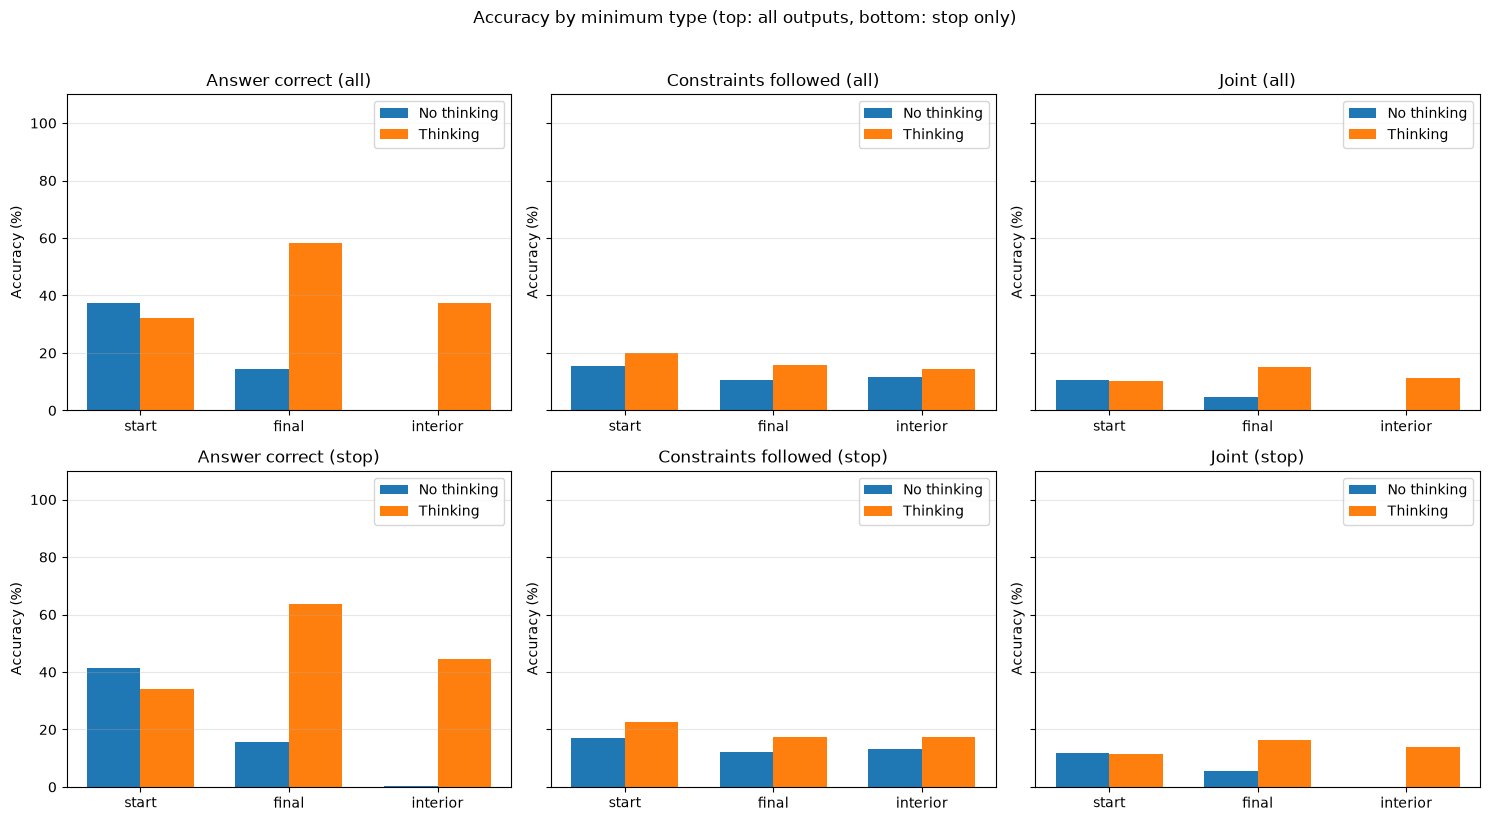

In [14]:
MIN_TYPES = ["start", "final", "interior"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for row_idx, (subset_name, subset) in enumerate([("all", df), ("stop", df[df["stop"]])]):
    for col_idx, (metric, label) in enumerate(zip(METRICS, METRIC_LABELS)):
        ax = axes[row_idx, col_idx]
        x = np.arange(len(MIN_TYPES))
        width = 0.36
        for offset, mode in zip([-width / 2, width / 2], MODE_ORDER):
            vals = (
                subset[subset["mode"] == mode]
                .groupby("min_type")[metric].mean()
                .reindex(MIN_TYPES) * 100
            )
            ax.bar(x + offset, vals.values, width, label=mode)
        ax.set_xticks(x)
        ax.set_xticklabels(MIN_TYPES)
        ax.set_title(f"{label} ({subset_name})")
        ax.set_ylabel("Accuracy (%)")
        ax.set_ylim(0, 110)
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
plt.suptitle("Accuracy by minimum type (top: all outputs, bottom: stop only)", y=1.02)
plt.tight_layout()
plt.show()


/tmp/ipykernel_635/1041742424.py:23: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(len(METRICS))
width = 0.36
for offset, mode in zip([-width / 2, width / 2], MODE_ORDER):
    values = summary.loc[mode, METRICS].to_numpy() * 100
    bars = ax.bar(x + offset, values, width, label=mode)
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1.0,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
ax.set_xticks(x)
ax.set_xticklabels(METRIC_LABELS)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 110)
ax.set_title(f"Arithmetic chain: thinking vs no thinking (all outputs, 5 per d×k cell, n={len(pilot_rows)})")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


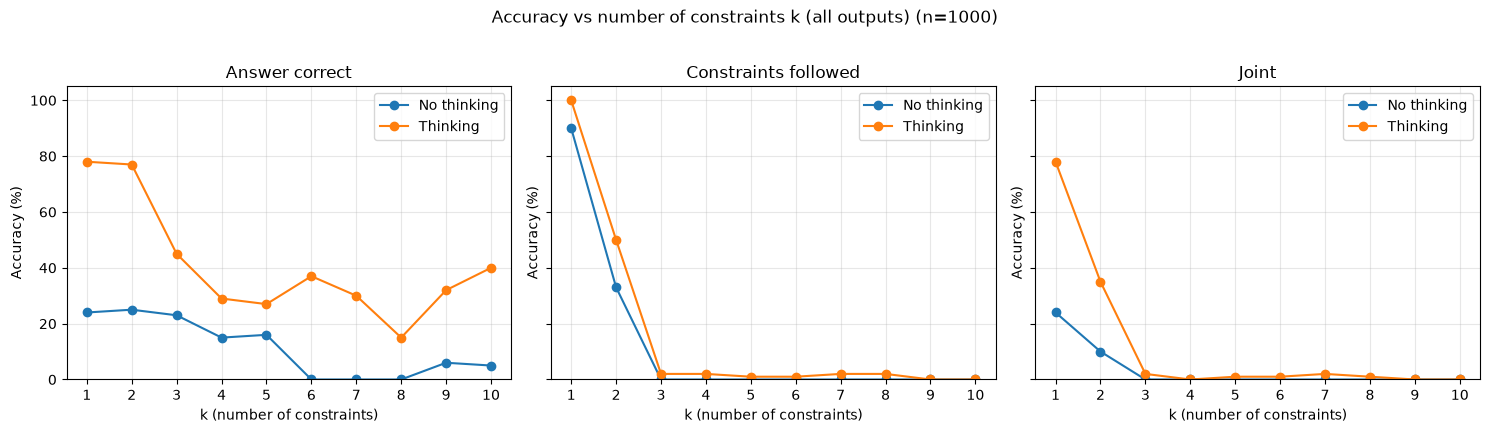

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, metric, label in zip(axes, METRICS, METRIC_LABELS):
    for mode in MODE_ORDER:
        series = df[df["mode"] == mode].groupby("k")[metric].mean() * 100
        ax.plot(series.index, series.values, marker="o", label=mode)
    ax.set_title(label)
    ax.set_xlabel("k (number of constraints)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle(f"Accuracy vs number of constraints k (all outputs) (n={len(pilot_rows)})", y=1.02)
plt.tight_layout()
plt.show()


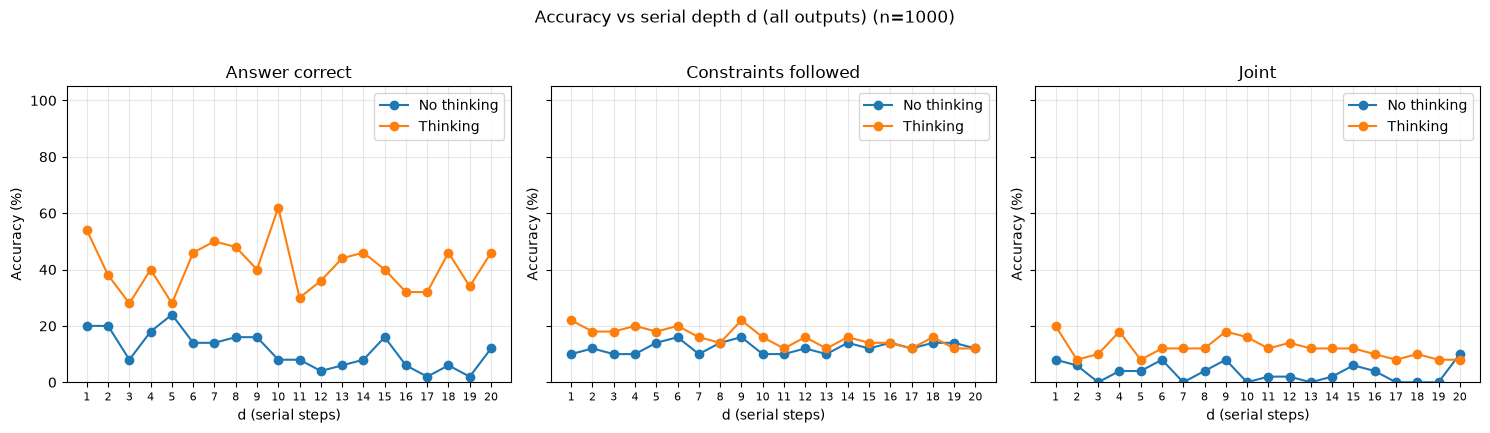

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, metric, label in zip(axes, METRICS, METRIC_LABELS):
    for mode in MODE_ORDER:
        series = df[df["mode"] == mode].groupby("d")[metric].mean() * 100
        ax.plot(series.index, series.values, marker="o", label=mode)
    ax.set_title(label)
    ax.set_xlabel("d (serial steps)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(range(1, 21))
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle(f"Accuracy vs serial depth d (all outputs) (n={len(pilot_rows)})", y=1.02)
plt.tight_layout()
plt.show()


=== per-constraint adherence (%): ALL outputs ===
mode        No thinking  Thinking
constraint                       
1                 84.80     81.80
2                 21.44     26.00
3                  0.00      2.12
4                 28.43     81.14
5                  2.67     26.17
6                 84.20     70.00
7                 87.50     75.00
8                  3.67     33.33
9                  0.00      0.50
10               100.00     72.00

=== denominator n: ALL ===
mode        No thinking  Thinking
constraint                       
1                  1000      1000
2                   900       900
3                   800       800
4                   700       700
5                   600       600
6                   500       500
7                   400       400
8                   300       300
9                   200       200
10                  100       100

=== per-constraint adherence (%): STOP only ===
mode        No thinking  Thinking
constraint             

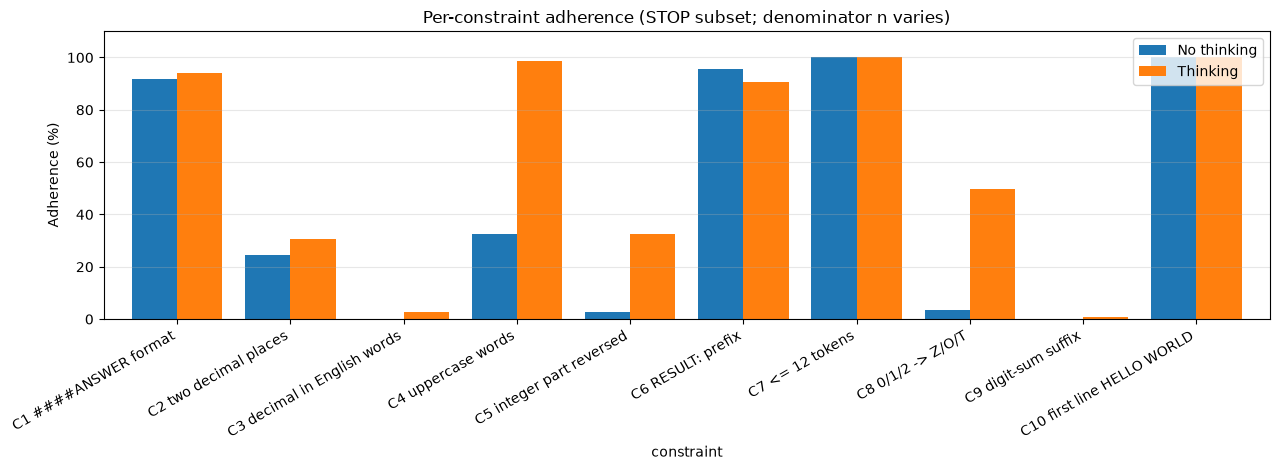

In [18]:
def _constraint_table(sub):
    rows = []
    for j in range(1, 11):
        s_j = sub[sub["k"] >= j]
        for mode in MODE_ORDER:
            s = s_j[s_j["mode"] == mode]
            rows.append({
                "constraint": j,
                "mode": mode,
                "rate": s[f"c{j}"].mean() * 100,
                "n": len(s),
            })
    table = pd.DataFrame(rows)
    pivot = table.pivot(index="constraint", columns="mode", values="rate").reindex(columns=MODE_ORDER)
    counts = table.pivot(index="constraint", columns="mode", values="n")
    return table, pivot, counts

constraint_all_df, pivot_all, n_all = _constraint_table(df)
constraint_stop_df, pivot_stop, n_stop = _constraint_table(df[df["stop"]])

print("=== per-constraint adherence (%): ALL outputs ===")
print(pivot_all.round(2).to_string())
print("\n=== denominator n: ALL ===")
print(n_all.to_string())
print("\n=== per-constraint adherence (%): STOP only ===")
print(pivot_stop.round(2).to_string())
print("\n=== denominator n: STOP only ===")
print(n_stop.to_string())

fig, ax = plt.subplots(figsize=(13, 4.8))
pivot_stop.plot(kind="bar", ax=ax, width=0.8)
ax.set_xticklabels(CONSTRAINT_NAMES, rotation=30, ha="right")
ax.set_ylabel("Adherence (%)")
ax.set_ylim(0, 110)
ax.set_title("Per-constraint adherence (STOP subset; denominator n varies)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="")
plt.tight_layout()
plt.show()


In [19]:
print("=== loop diagnostics ===")
df["has321"] = df["answer_text"].str.contains("321", regex=False)
df["multi_marker"] = df["answer_text"].str.count("####ANSWER") >= 3
for mode in MODE_ORDER:
    s = df[df["mode"] == mode]
    print(f"{mode:12s} n={len(s):4d} trunc={int(s['trunc'].sum()):4d} "
          f"has321={int(s['has321'].sum()):4d} multi_marker={int(s['multi_marker'].sum()):4d}")
print("\n=== by k: truncation / 321 / repeated marker (%) ===")
for mode in MODE_ORDER:
    s = df[df["mode"] == mode]
    tab = s.groupby("k")[["trunc", "has321", "multi_marker"]].mean() * 100
    print(f"\n[{mode}]")
    print(tab.round(1).to_string())


=== loop diagnostics ===
No thinking  n=1000 trunc= 111 has321=   0 multi_marker= 157
Thinking     n=1000 trunc= 140 has321=   0 multi_marker=  14

=== by k: truncation / 321 / repeated marker (%) ===

[No thinking]
    trunc  has321  multi_marker
k                              
1     0.0     0.0           0.0
2     0.0     0.0           0.0
3     4.0     0.0           9.0
4     0.0     0.0           4.0
5     7.0     0.0          14.0
6     0.0     0.0           0.0
7     2.0     0.0           8.0
8     4.0     0.0           8.0
9    18.0     0.0          35.0
10   76.0     0.0          79.0

[Thinking]
    trunc  has321  multi_marker
k                              
1     0.0     0.0           0.0
2     0.0     0.0           0.0
3     5.0     0.0           0.0
4     2.0     0.0           0.0
5     7.0     0.0           0.0
6    12.0     0.0           0.0
7    13.0     0.0           2.0
8    31.0     0.0           1.0
9    37.0     0.0           6.0
10   33.0     0.0           5.0


In [20]:
print("=== answer wrong (first 3, thinking) ===")
for _, rec in df[(df["mode"] == "Thinking") & (~df["answer_correct"])].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']} finish={rec['finish_reason']} ntok={rec['n_tokens']}")
    print("answer_text:", repr(rec["answer_text"][:600]))
    print("thinking_text (tail):", repr(rec["thinking_text"][-400:]))

print("\n=== answer correct but constraints fail (first 3, thinking) ===")
mask = (df["mode"] == "Thinking") & df["answer_correct"] & (~df["constraint_all"])
for _, rec in df[mask].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']}")
    failed = [i for i in range(1, int(rec["k"]) + 1) if not bool(rec[f"c{i}"])]
    print("failed:", failed)
    print("answer_text:", repr(rec["answer_text"][:600]))

print("\n=== C2/C3 failures at k>=3 (first 3, thinking) ===")
c23_mask = (df["mode"] == "Thinking") & (df["k"] >= 3) & ((~df["c2"].astype(bool)) | (~df["c3"].astype(bool)))
for _, rec in df[c23_mask].head(3).iterrows():
    print("-" * 80)
    print(f"d={rec['d']} k={rec['k']} i={rec['i']} ans={rec['ans']} dec_kind={rec['dec_kind']} dec_digits={rec['dec_digits']!r}")
    print("answer_text:", repr(rec["answer_text"][:600]))


=== answer wrong (first 3, thinking) ===
--------------------------------------------------------------------------------
d=1 k=3 i=1 ans=-38.2 finish=stop ntok=1779
answer_text: '####ANSWER=-THIRTY-EIGHT ZERO'
thinking_text (tail): 't I need to check if the problem expects the answer as -38.2, which is -38.20. So the answer is -38.20, which is written as -THIRTY-EIGHT ZERO. But the user might have a different expectation. Alternatively, maybe the question is a trick question where the minimum value is the starting value, but that seems unlikely. So I think the correct answer is -38.20, which is written as -THIRTY-EIGHT ZERO.\n'
--------------------------------------------------------------------------------
d=1 k=3 i=2 ans=5.6 finish=stop ntok=925
answer_text: '####ANSWER=5.6.ZERO'
thinking_text (tail): 'e operations, I can\'t do that. So the answer is 5.6. But the user might have intended to ask for the result after applying the operation, which is 40.9. But the question specifically